In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Load the dataset directly from the provided URL
url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
df = pd.read_csv(url)

#2
categorical_cols = list(df.dtypes[df.dtypes == 'object'].index)
numerical_cols = list(df.dtypes[df.dtypes != 'object'].index)

# Fill categorical missing values with 'NA'
df[categorical_cols] = df[categorical_cols].fillna('NA')

# Fill numerical missing values with 0.0
df[numerical_cols] = df[numerical_cols].fillna(0.0)

# 3. Split the data into train/val/test using your exact calls
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

# Reset indices for clean dataframes
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

# Print the sizes to confirm the split worked
print(f"Train size: {len(df_train)}")
print(f"Validation size: {len(df_val)}")
print(f"Test size: {len(df_test)}")

Train size: 3000
Validation size: 1000
Test size: 1000


In [4]:
from sklearn.metrics import roc_auc_score

# The numerical features we want to evaluate
features_to_check = [
    'lead_score', 
    'number_of_courses_viewed', 
    'interaction_count', 
    'annual_income'
]

auc_scores = {}

for feature in features_to_check:
    # Calculate the initial AUC score
    auc = roc_auc_score(df_train['converted'], df_train[feature])
    
    # Invert the variable if AUC is less than 0.5 (handling negative correlation)
    if auc < 0.5:
        auc = roc_auc_score(df_train['converted'], -df_train[feature])
        
    auc_scores[feature] = auc
    print(f"{feature}: {auc:.4f}")

# Identify the feature with the highest score
best_feature = max(auc_scores, key=auc_scores.get)
print(f"\nFeature with the highest AUC: {best_feature}")

lead_score: 0.7882
number_of_courses_viewed: 0.7230
interaction_count: 0.7649
annual_income: 0.6082

Feature with the highest AUC: lead_score


In [5]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# 1. Isolate the target variable and drop it from the feature sets
y_train = df_train['converted'].values
y_val = df_val['converted'].values

df_train_features = df_train.drop(columns=['converted'])
df_val_features = df_val.drop(columns=['converted'])

# 2. Convert DataFrames to lists of dictionaries
train_dicts = df_train_features.to_dict(orient='records')
val_dicts = df_val_features.to_dict(orient='records')

# 3. Apply one-hot-encoding using DictVectorizer
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

# 4. Train the logistic regression model with the specified parameters
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=1)
model.fit(X_train, y_train)

# 5. Predict probabilities on the validation set 
# (use [:, 1] to get the probability of the positive class)
y_pred_val = model.predict_proba(X_val)[:, 1]

# 6. Calculate and round the ROC AUC score
auc_score = roc_auc_score(y_val, y_pred_val)
print(f"Validation AUC: {round(auc_score, 3)}")

Validation AUC: 0.732


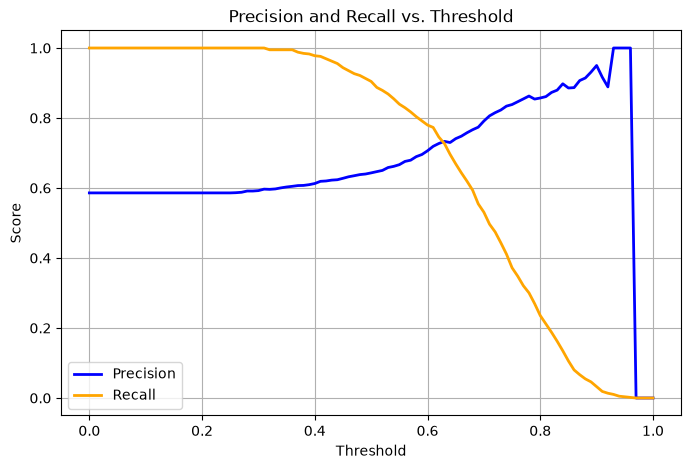

Intersection threshold: 0.63


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score

# 1. Create an array of thresholds from 0.0 to 1.0 with step 0.01
thresholds = np.linspace(0, 1, 101)

precisions = []
recalls = []

# 2. Compute Precision and Recall for each threshold
for t in thresholds:
    # Convert probabilities to binary predictions based on the current threshold
    preds = (y_pred_val >= t).astype(int)
    
    # Calculate scores (zero_division=0 prevents warnings when there are no positive predictions)
    p = precision_score(y_val, preds, zero_division=0)
    r = recall_score(y_val, preds, zero_division=0)
    
    precisions.append(p)
    recalls.append(r)

# 3. Plot the curves
plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions, label='Precision', color='blue', linewidth=2)
plt.plot(thresholds, recalls, label='Recall', color='orange', linewidth=2)
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs. Threshold')
plt.legend()
plt.grid(True)
plt.show()

# 4. Find the intersection threshold
# We want the smallest absolute difference, ignoring where both are 0
min_diff = float('inf')
intersect_threshold = None

for p, r, t in zip(precisions, recalls, thresholds):
    if p == 0 and r == 0:
        continue
    
    diff = abs(p - r)
    if diff < min_diff:
        min_diff = diff
        intersect_threshold = t

print(f"Intersection threshold: {intersect_threshold:.2f}")

Threshold with the maximal F1 score: 0.41
Max F1 Score: 0.7576


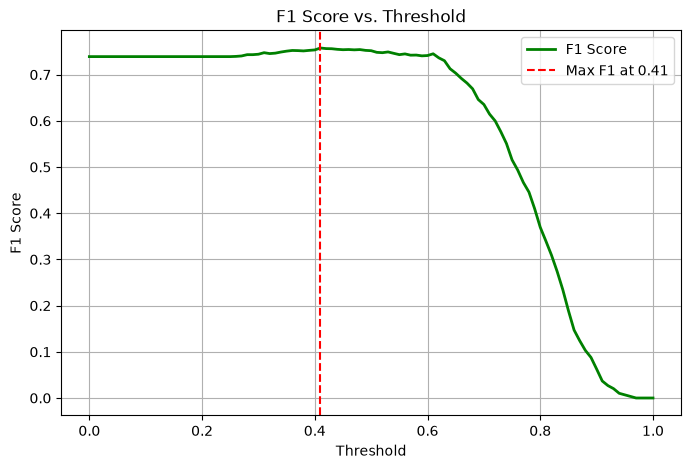

In [7]:
import matplotlib.pyplot as plt

f1_scores = []

# 1. Compute F1 score for each threshold
for p, r in zip(precisions, recalls):
    # Prevent division by zero
    if (p + r) == 0:
        f1_scores.append(0.0)
    else:
        f1 = 2 * p * r / (p + r)
        f1_scores.append(f1)

# 2. Find the threshold that gives the maximum F1 score
max_f1 = max(f1_scores)
max_idx = f1_scores.index(max_f1)
best_threshold = thresholds[max_idx]

print(f"Threshold with the maximal F1 score: {best_threshold:.2f}")
print(f"Max F1 Score: {max_f1:.4f}")

# 3. (Optional) Plot F1 score to visualize the peak
plt.figure(figsize=(8, 5))
plt.plot(thresholds, f1_scores, label='F1 Score', color='green', linewidth=2)
plt.axvline(x=best_threshold, color='red', linestyle='--', label=f'Max F1 at {best_threshold:.2f}')
plt.xlabel('Threshold')
plt.ylabel('F1 Score')
plt.title('F1 Score vs. Threshold')
plt.legend()
plt.grid(True)
plt.show()

In [8]:
import numpy as np
from sklearn.model_selection import KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# 1. Initialize KFold
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

auc_scores = []

# 2. Iterate over the folds
for train_idx, val_idx in kfold.split(df_full_train):
    
    # Split the data into train and validation for this fold
    df_train_fold = df_full_train.iloc[train_idx]
    df_val_fold = df_full_train.iloc[val_idx]
    
    # Isolate targets
    y_train_fold = df_train_fold['converted'].values
    y_val_fold = df_val_fold['converted'].values
    
    # Drop target from features
    df_train_features = df_train_fold.drop(columns=['converted'])
    df_val_features = df_val_fold.drop(columns=['converted'])
    
    # Apply DictVectorizer
    dv = DictVectorizer(sparse=False)
    X_train_fold = dv.fit_transform(df_train_features.to_dict(orient='records'))
    X_val_fold = dv.transform(df_val_features.to_dict(orient='records'))
    
    # Train the model
    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=1)
    model.fit(X_train_fold, y_train_fold)
    
    # Predict and calculate AUC
    y_pred_fold = model.predict_proba(X_val_fold)[:, 1]
    auc = roc_auc_score(y_val_fold, y_pred_fold)
    
    # Store the score
    auc_scores.append(auc)

# 3. Compute and print the standard deviation
std_dev = np.std(auc_scores)

print("AUC scores for each fold:", [round(score, 4) for score in auc_scores])
print(f"Standard Deviation of AUC: {round(std_dev, 3)}")

AUC scores for each fold: [0.7305, 0.7297, 0.7363, 0.7413, 0.721]
Standard Deviation of AUC: 0.007


In [9]:
import numpy as np
from sklearn.model_selection import KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# The C values to test
C_values = [0.000001, 0.001, 1]

# Initialize KFold exactly as before
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

results = []

for C in C_values:
    auc_scores = []
    
    # 5-Fold Cross Validation
    for train_idx, val_idx in kfold.split(df_full_train):
        
        df_train_fold = df_full_train.iloc[train_idx]
        df_val_fold = df_full_train.iloc[val_idx]
        
        y_train_fold = df_train_fold['converted'].values
        y_val_fold = df_val_fold['converted'].values
        
        df_train_features = df_train_fold.drop(columns=['converted'])
        df_val_features = df_val_fold.drop(columns=['converted'])
        
        dv = DictVectorizer(sparse=False)
        X_train_fold = dv.fit_transform(df_train_features.to_dict(orient='records'))
        X_val_fold = dv.transform(df_val_features.to_dict(orient='records'))
        
        model = LogisticRegression(solver='liblinear', C=C, max_iter=1000, random_state=1)
        model.fit(X_train_fold, y_train_fold)
        
        y_pred_fold = model.predict_proba(X_val_fold)[:, 1]
        auc = roc_auc_score(y_val_fold, y_pred_fold)
        auc_scores.append(auc)
        
    # Calculate mean and std, rounded to 3 decimal places
    mean_auc = round(np.mean(auc_scores), 3)
    std_auc = round(np.std(auc_scores), 3)
    
    print(f"C = {C:<8} | Mean AUC: {mean_auc:.3f} | Std: {std_auc:.3f}")
    
    # Store for finding the best
    results.append((mean_auc, std_auc, C))

# Apply the sorting logic:
# 1. Highest Mean AUC
# 2. Lowest Std (we use negative to sort ascending while keeping mean descending)
# 3. Smallest C (also negative)
best_result = max(results, key=lambda x: (x[0], -x[1], -x[2]))

print(f"\nBest C: {best_result[2]}")

C = 1e-06    | Mean AUC: 0.617 | Std: 0.019
C = 0.001    | Mean AUC: 0.749 | Std: 0.010
C = 1        | Mean AUC: 0.732 | Std: 0.007

Best C: 0.001
